In [1]:
import pandas as pd
import numpy as np
import mlflow

d:\DSWITHBAPPY\END-TO-END MLFLOW PROJECT\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../content/final_df.csv")

In [4]:
df

,detail_text,label
0,"As U.S. budget fight looms, Republicans flip t...",0
1,U.S. military to accept transgender recruits o...,0
2,Senior U.S. Republican senator: 'Let Mr. Muell...,0
3,FBI Russia probe helped by Australian diplomat...,0
4,Trump wants Postal Service to charge 'much mor...,0
...,...,...
39100,The White House and The Theatrics of ‘Gun Cont...,1
39101,Activists or Terrorists? How Media Controls an...,1
39102,"BOILER ROOM – No Surrender, No Retreat, Heads ...",1
39103,Federal Showdown Looms in Oregon After BLM Abu...,1


In [5]:
import nltk
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to C:\Users\SAHIL
[nltk_data]     KATVE\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\SAHIL
[nltk_data]     KATVE\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [6]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [7]:
def preprocess_comment(comment):
    # Convert to lowercase
    comment = comment.lower()

    # Remove trailing and leading whitespaces
    comment = comment.strip()

    # Remove newline characters
    comment = re.sub(r'\n', ' ', comment)

    # Remove non-alphanumeric characters, except punctuation
    comment = re.sub(r'[^A-Za-z0-9\s!?.,]', '', comment)

    # Remove stopwords but retain important ones for sentiment analysis
    stop_words = set(stopwords.words('english'))
    comment = ' '.join([word for word in comment.split() if word not in stop_words])

    # Lemmatize the words
    lemmatizer = WordNetLemmatizer()
    comment = ' '.join([lemmatizer.lemmatize(word) for word in comment.split()])

    return comment

In [8]:
df['detail_text'][0]

'As U.S. budget fight looms, Republicans flip their fiscal script WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fiscal conservative” on Sunday and urged budget restraint in 2018. In keeping with a sharp pivot under way among Republicans, U.S. Representative Mark Meadows, speaking on CBS’ “Face the Nation,” drew a hard line on federal spending, which lawmakers are bracing to do battle over in January. When they return from the holidays on Wednesday, lawmakers will begin trying to pass a federal budget in a fight likely to be linked to other issues, such as immigration policy, even as the November congressional election campaigns approach in which Republicans will seek to keep control of Congress. President Donald Trump and his Republicans want a big budget increase in military spending, while Democrats also want proportional increases for non

In [9]:
df['detail_text'] = df['detail_text'].map(preprocess_comment)

In [10]:
df['detail_text'][0]

'u.s. budget fight looms, republican flip fiscal script washington reuters head conservative republican faction u.s. congress, voted month huge expansion national debt pay tax cuts, called fiscal conservative sunday urged budget restraint 2018. keeping sharp pivot way among republicans, u.s. representative mark meadows, speaking cbs face nation, drew hard line federal spending, lawmaker bracing battle january. return holiday wednesday, lawmaker begin trying pas federal budget fight likely linked issues, immigration policy, even november congressional election campaign approach republican seek keep control congress. president donald trump republican want big budget increase military spending, democrat also want proportional increase nondefense discretionary spending program support education, scientific research, infrastructure, public health environmental protection. trump administration already willing say going increase nondefense discretionary spending ... 7 percent, meadows, chairm

In [11]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

In [12]:
X = df.drop(columns=['label'])
y = df['label']

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

In [15]:
vectorizer = CountVectorizer(max_features=30000)

vectorizer.fit(X_train['detail_text'])

,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",30000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (strip_accents and lowercase) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"stop_words stop_words: {'english'}, list, default=NoneIf 'english', a built-in stop word list for English is used.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",None
,"token_pattern token_pattern: str or None, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp select tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",'(?u)\\b\\w\\w+\\b'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentword n-grams or char n-grams to be extracted. All values of n suchsuch that min_n <= n <= max_n will be used. For example an``ngram_range`` of ``(1, 1)`` means only unigrams, ``(1, 2)`` meansunigrams and bigrams, and ``(2, 2)`` means only bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"


In [16]:
print(len(vectorizer.vocabulary_))
vectorizer.vocabulary_

30000


{'highlight': np.int64(13059),
 'trump': np.int64(27661),
 'presidency': np.int64(21023),
 'march': np.int64(16835),
 '12': np.int64(68),
 'est': np.int64(9859),
 'reuters': np.int64(22935),
 'day': np.int64(7477),
 'president': np.int64(21024),
 'donald': np.int64(8747),
 'administration': np.int64(1488),
 'sunday': np.int64(26239),
 'aide': np.int64(1713),
 'attack': np.int64(2899),
 'credibility': np.int64(7070),
 'nonpartisan': np.int64(18733),
 'agency': np.int64(1656),
 'analyze': np.int64(2138),
 'cost': np.int64(6869),
 'replacement': np.int64(22633),
 'obamacare': np.int64(18951),
 'white': np.int64(29379),
 'house': np.int64(13365),
 'seek': np.int64(24086),
 'quell': np.int64(21698),
 'opposition': np.int64(19302),
 'many': np.int64(16814),
 'conservative': np.int64(6506),
 'republicans': np.int64(22692),
 'two': np.int64(27827),
 'attorney': np.int64(2929),
 'preet': np.int64(20945),
 'bharara': np.int64(3756),
 'fired': np.int64(10788),
 'tried': np.int64(27596),
 'call': 

In [17]:
X_train_vec = vectorizer.transform(X_train['detail_text'])
X_test_vec = vectorizer.transform(X_test['detail_text'])

In [18]:
print(f"Train Shape : {X_train_vec.shape}")
print(f"Test Shape : {X_test_vec.shape}")

Train Shape : (31284, 30000)
Test Shape : (7821, 30000)


In [19]:
import mlflow
import mlflow.sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score,
                            confusion_matrix, 
                            classification_report)
from mlflow import MlflowClient


2026/11/02 13:59:28 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/02 13:59:36 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run RandomForest_baseline_vectorization at: http://127.0.0.1:5000/#/experiments/1/runs/bbc79e94760a4adea8786e12e9896174
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


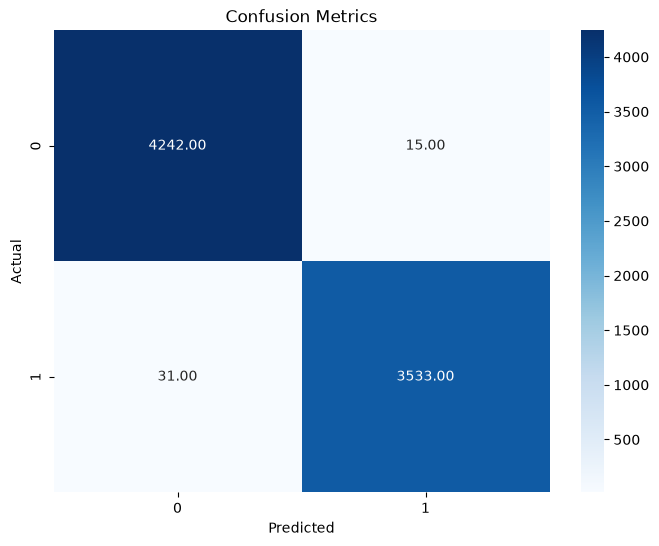

In [21]:
mlflow.set_tracking_uri("http://127.0.0.1:5000/")

mlflow.set_experiment("RF Baseline Model")

with mlflow.start_run():
    mlflow.set_tag("mlflow.runName","RandomForest_baseline_vectorization")
    mlflow.set_tag("experiment_type","baseline")
    mlflow.set_tag("model_type","RandomForestClassifier")

    mlflow.set_tag("description", "Baseline RandomForest model for sentiment analysis using Bag of Words (BoW) with a simple train-test split")

    mlflow.log_param("vectorizer_type","CountVectorizer")
    mlflow.log_param("vectorizer_max_feature",vectorizer.max_features)

    model = RandomForestClassifier(random_state=42)

    mlflow.log_param("random_state",42)

    model.fit(X_train_vec,y_train)


    y_pred = model.predict(X_test_vec)

    accuracy = accuracy_score(y_test,y_pred)
    mlflow.log_metric("accuracy",accuracy)

    classific_report = classification_report(y_test,y_pred, output_dict=True)

    for label, metrics in classific_report.items():
        if isinstance(metrics, dict):
            for metric, value in metrics.items():
                mlflow.log_metric(f"{label}_{metric}",value)

    confusion_mat = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(confusion_mat, annot=True, fmt=".2f", cmap="Blues")
    plt.title("Confusion Metrics")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.savefig("../content/basemodel_confusion_metrics.png")
    mlflow.log_artifact("../content/basemodel_confusion_metrics.png")

    mlflow.sklearn.log_model(
        sk_model=model,
        name="random_forest_model",
        serialization_format="pickle"    
    )

    
    mlflow.log_artifact("../content/True.csv")
    mlflow.log_artifact("../content/Fake.csv")

In [22]:
mlflow.sklearn.log_model(
    sk_model=model,
    name="random_forest_model",
    registered_model_name="random_forest_model",
    serialization_format="pickle"
)

2026/11/02 13:59:59 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/02 14:00:05 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'random_forest_model' already exists. Creating a new version of this model...
2026/11/02 14:00:05 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: random_forest_model, version 2
Created version '2' of model 'random_forest_model'.


In [ ]:
df.to_csv("../content/reddit_preprocessing.csv",index=False)